In [40]:
# Cell 1: Importing required libraries
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import balanced_accuracy_score, precision_score, f1_score
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
import time


In [41]:

# Cell 2: Generating and preprocessing the dataset
# Create a binary classification dataset
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, n_informative=10, random_state=42)

# Convert the data to tensors
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create DataLoader objects for training and testing data
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


In [42]:

# Cell 3: Defining the neural network
class SimpleNN(nn.Module):
    def __init__(self, input_size):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 2)  # Binary classification

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x


In [43]:
def evaluate(model, data_loader):
    model.eval()  # Set the model to evaluation mode
    all_labels = []
    all_predictions = []

    with torch.no_grad():  # Disable gradient computation
        for x_batch, y_batch in data_loader:
            outputs = model(x_batch)
            _, predicted = torch.max(outputs.data, 1)
            all_labels.extend(y_batch.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())

    # Calculate metrics
    balanced_accuracy = balanced_accuracy_score(all_labels, all_predictions)
    precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
    f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

    return balanced_accuracy, precision, f1

In [44]:
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    train_metrics = {'accuracy': [], 'precision': [], 'f1': []}
    val_metrics = {'accuracy': [], 'precision': [], 'f1': []}

    for epoch in range(num_epochs):
        start_time = time.time()  # Start time for epoch

        model.train()  # Set the model to training mode
        total_loss = 0

        for x_batch, y_batch in train_loader:
            
            optimizer.zero_grad()  # Zero the parameter gradients
            outputs = model(x_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()  # Backpropagation
            optimizer.step()  # Optimize
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}')

        # Evaluate on the training and validation sets
        train_acc, train_prec, train_f1 = evaluate(model, train_loader)
        val_acc, val_prec, val_f1 = evaluate(model, val_loader)

        # Store metrics
        train_metrics['accuracy'].append(train_acc)
        train_metrics['precision'].append(train_prec)
        train_metrics['f1'].append(train_f1)

        val_metrics['accuracy'].append(val_acc)
        val_metrics['precision'].append(val_prec)
        val_metrics['f1'].append(val_f1)
    
    return train_metrics, val_metrics


In [50]:

# Cell 4: Initializing the model, loss function, and optimizer
model = SimpleNN(input_size=20)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [51]:

# Cell 6: Training the model
epochs = 100
train_metrics, val_metrics = train(model, train_loader, test_loader, criterion, optimizer, epochs)


Epoch [1/100], Loss: 0.7445
Epoch [2/100], Loss: 0.5786
Epoch [3/100], Loss: 0.4579
Epoch [4/100], Loss: 0.3716
Epoch [5/100], Loss: 0.3097
Epoch [6/100], Loss: 0.2680
Epoch [7/100], Loss: 0.2366
Epoch [8/100], Loss: 0.2129
Epoch [9/100], Loss: 0.1945
Epoch [10/100], Loss: 0.1783
Epoch [11/100], Loss: 0.1657
Epoch [12/100], Loss: 0.1542
Epoch [13/100], Loss: 0.1461
Epoch [14/100], Loss: 0.1351
Epoch [15/100], Loss: 0.1278
Epoch [16/100], Loss: 0.1215
Epoch [17/100], Loss: 0.1150
Epoch [18/100], Loss: 0.1092
Epoch [19/100], Loss: 0.1052
Epoch [20/100], Loss: 0.1014
Epoch [21/100], Loss: 0.0960
Epoch [22/100], Loss: 0.0916
Epoch [23/100], Loss: 0.0877
Epoch [24/100], Loss: 0.0841
Epoch [25/100], Loss: 0.0804
Epoch [26/100], Loss: 0.0774
Epoch [27/100], Loss: 0.0740
Epoch [28/100], Loss: 0.0722
Epoch [29/100], Loss: 0.0689
Epoch [30/100], Loss: 0.0670
Epoch [31/100], Loss: 0.0664
Epoch [32/100], Loss: 0.0635
Epoch [33/100], Loss: 0.0605
Epoch [34/100], Loss: 0.0576
Epoch [35/100], Loss: 0

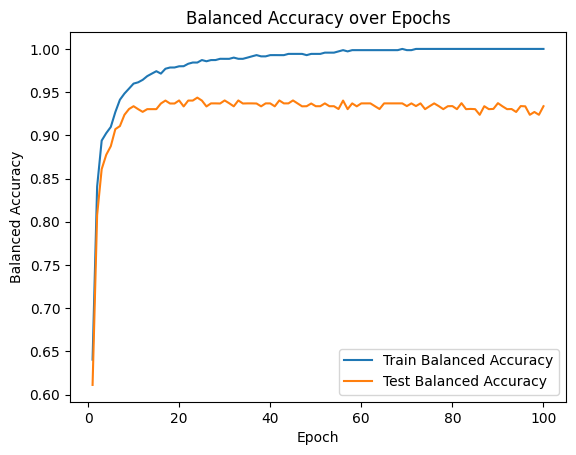

In [52]:

# Cell 7: Plotting the results (optional)
plt.plot(range(1, epochs+1), train_metrics['accuracy'], label='Train Balanced Accuracy')
plt.plot(range(1, epochs+1), val_metrics['accuracy'], label='Test Balanced Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Balanced Accuracy')
plt.title('Balanced Accuracy over Epochs')
plt.legend()
plt.show()
